In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))  # go up one dir from examples/

In [2]:
from math import sin, cos, tan, sqrt, pi
from copy import deepcopy
from importlib import reload
import yaml

import numpy as np
import matplotlib.pyplot as plt
import splinecloud_scipy as scloud
import cadquery as cq
from jupyter_cadquery import show

from cquav.wing.airfoil import Airfoil, load_airfoils_collection
from cquav.wing.profiles.airfoil_section import AirfoilSection
from cquav.wing import twospar_console as tsc
from cquav.materials import IsotropicMaterial, FluidProperties
from cquav.wing.airfoil.airfoil import Airfoil
from cquav.wing.meta.aero import NormalizedCoeffDistribution, WingSpanEfficiency
from cquav.wing.meta.geom import Wing
from cquav.wing.meta.experiments import AeroLoadCollection

%matplotlib notebook

Overwriting auto display for cadquery Workplane and Shape


## Constants

In [3]:
## Physical constants

AIR_DENSITY = 1.225 #[kg/m^3]
STANDARD_GRAVITY = 9.80665 ## [m/s]
AIR_KINEMATIC_VISCOSITY_SEA_LEVEL = 1.460*1e-5 ## [m^2/s]

DELTA_MAX = 0.1 ## relative wing tip displacement
G = 9.81 ## [m/s**2]
LOAD_FACTOR = 1.0

## Wing Geometry

CHORD_MIN = 50
CHORD_MAX = 1000
CHORD_DEFAULT = 260

SPAN_MIN = 50
SPAN_MAX = 5000
SPAN_DEFAULT = 900

VELOCITY = 35 #[m/s]
SPEED_OF_SOUND = 340 #[m/s]
MACH = VELOCITY/SPEED_OF_SOUND

DYN_AIR_PRESSURE = 0.5 * AIR_DENSITY * VELOCITY**2 ## dynamic pressure

PAYLOAD_MASS = 20 # [kg]

## Load and prepare meta models

**Construct function for the chord-scaled normalized lift coefficient distribution**

In [4]:
collection = AeroLoadCollection("../cquav/wing/meta/wing_load_curves.yaml")

In [5]:
experiment = collection.get_experiment(
    root_airfoil="NACA4412",
    tip_airfoil="NACA4412",
    tip_twist=0,
    sa_re=0,
)

In [6]:
ccls_curve_tr05_aoa1 = experiment.get_curves_for_tr_aoa(0.5, 1.0)

In [7]:
ccls_curve_tr05_aoa1

{6: 'spl_c8pvb3hpEQE3',
 7: 'spl_L3Osxw7V9pSR',
 8: 'spl_KzStgIt7hJND',
 9: 'spl_i1b5nkLEbeiC',
 10: 'spl_J7KTUqSbtacs'}

In [8]:
alpha = 1.0
ncl_surfaces = {}
for tr_val in experiment.list_tr_values():
    ccls_curves = experiment.get_curves_for_tr_aoa(tr_val, alpha)
    ccls_surf = NormalizedCoeffDistribution(ccls_curves)
    ncl_surfaces[f"TR={tr_val}"] = ccls_surf

<IPython.core.display.Javascript object>


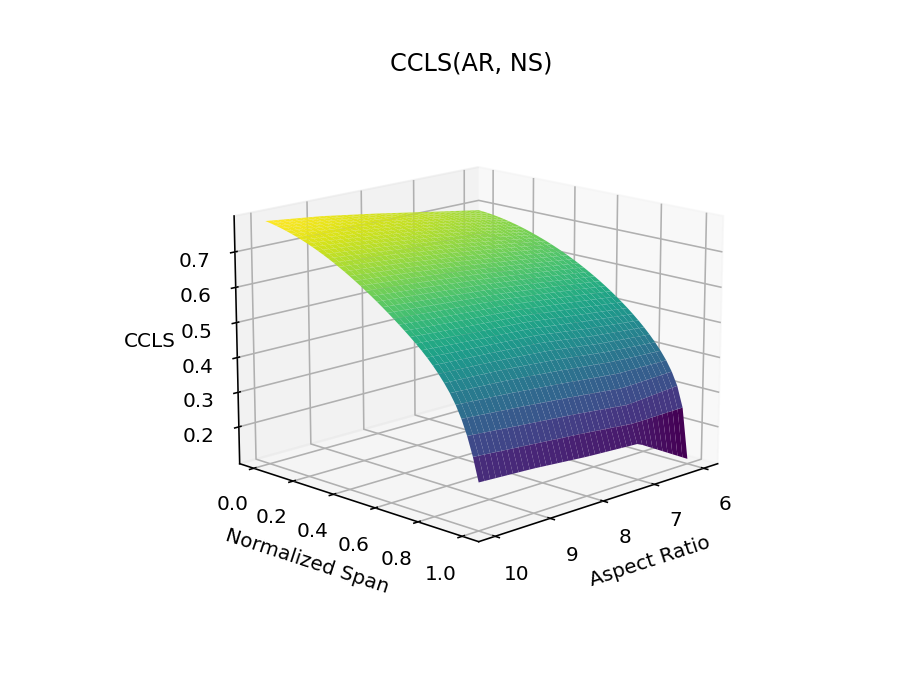

In [9]:
ncl_surfaces["TR=0.5"].surfplot()

**Load wing span efficiency data**

In [10]:
with open("../cquav/wing/meta/span_efficiency.yaml", "r") as f:
    span_efficiency_data = yaml.safe_load(f)

In [11]:
span_efficiency_data["delta"]

{4: 'spl_IvdZRtwoGU6T',
 6: 'spl_VsE31rIqsGtH',
 8: 'spl_YUtYmXHXXK5Q',
 10: 'spl_Nb5m075aHe42'}

In [12]:
span_efficiency = WingSpanEfficiency(span_efficiency_data["delta"])

<IPython.core.display.Javascript object>


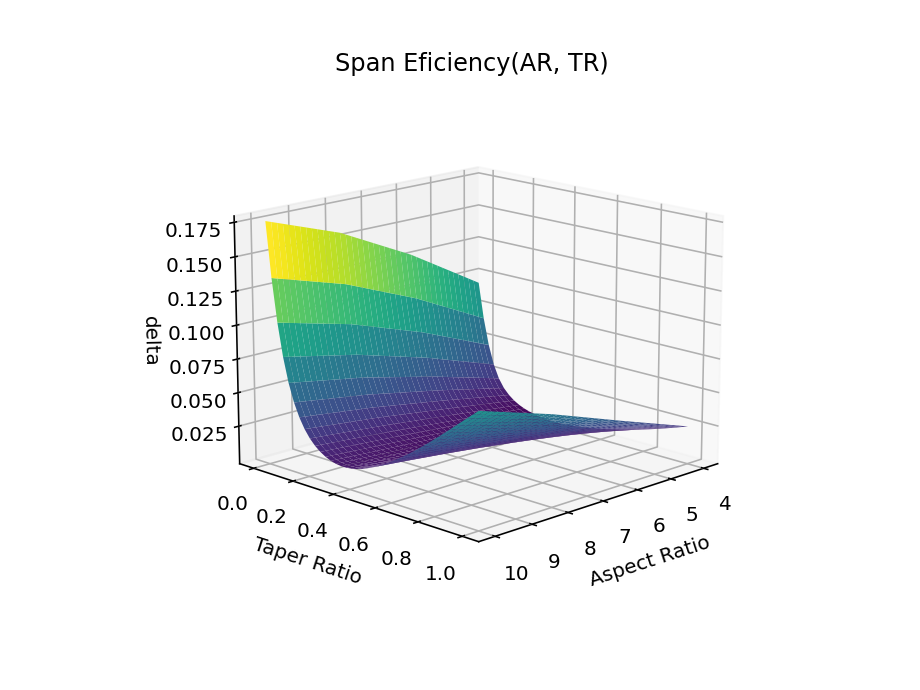

In [13]:
span_efficiency.surfplot()

**Create airfoil object**

In [14]:
airfoils_collection = load_airfoils_collection()
airfoil_data = airfoils_collection["NACA 4 digit airfoils"]["NACA 4412 (naca4412-il)"]

In [15]:
naca4412 = Airfoil(airfoil_data)

In [16]:
alpha_max_lift = naca4412.alpha_max_lift(1e6)
alpha_max_lift

16.255906111873184

In [17]:
alpha_min_drag = naca4412.alpha_min_drag(1e6)
alpha_min_drag

1.179952243052381

In [18]:
naca4415 = Airfoil(airfoils_collection["NACA 4 digit airfoils"]["NACA 4415 (naca4415-il)"])

In [19]:
naca4415_alpha_max_lift = naca4415.alpha_max_lift(1e6)
naca4415_alpha_max_lift

15.757506477671086

In [20]:
naca4415_alpha_min_drag = naca4415.alpha_min_drag(1e6)
naca4415_alpha_min_drag

1.7662449829802378

## Build wing console

**Materials**

In [21]:
Nylon = IsotropicMaterial(1120, 45*1e6, 2.59*1e9)

XPS_foam = IsotropicMaterial(30, 1e3, 25*1e6)
# https://www.mdpi.com/2073-4360/12/1/47

Fiberglass_laminate = IsotropicMaterial(1800, 290*1e6, 12.4*1e9)
#https://laminatedplastics.com/fiberglasslaminates.pdf

Carbon_laminate = IsotropicMaterial(1500, 450*1e6, 35*1e9)
# https://www.researchgate.net/publication/259461841_Mechanical_Properties_of_Carbon_FiberEpoxy_Composites_Effects_of_Number_of_Plies_Fiber_Contents_and_Angle-Ply_Layers

In [22]:
reload(tsc)

<module 'cquav.wing.twospar_console' from '/home/frantic/splinecloud/demo_copter/cq-uav/cquav/wing/twospar_console.py'>

### 1. Build wing console with shell

In [23]:
materials = {
    "spar": Carbon_laminate, 
    "shell": Fiberglass_laminate, 
    "foam": XPS_foam
}
tr = 0.5
ar = 9
ccls_surf = ncl_surfaces[f"TR={tr}"].ccls_by_ar_ns

In [24]:
wing_console = tsc.TwoSparWingConsole(
    ccls_surf, span_efficiency, naca4412,
    span=2150, sweep_angle=7.6, aspect_ratio=ar, taper_ratio=tr,
    front_spar_thickness=2.0, rear_spar_thickness=2.0, tip_twist_angle=3,
    shell_thickness=0.3, materials=materials
)

In [25]:
assy = cq.Assembly()
assy.add(wing_console.foam, name="foam", color=cq.Color("lightgray"))
assy.add(wing_console.front_spar, name="front_spar", color=cq.Color("yellow"))
assy.add(wing_console.rear_spar, name="rear_spar", color=cq.Color("yellow"))
assy.add(wing_console.shell, name="shell", color=cq.Color("lightskyblue2"))
assy.add(wing_console.aero_center, name="aero_center", color=cq.Color("blue"))
show(assy, angular_tolerance=0.1)

100% ⋮————————————————————————————————————————————————————————————⋮ (5/5)  3.76s


CadViewerWidget(anchor=None, cad_width=800, glass=False, height=600, pinning=False, theme='light', title=None,…

<IPython.core.display.Javascript object>


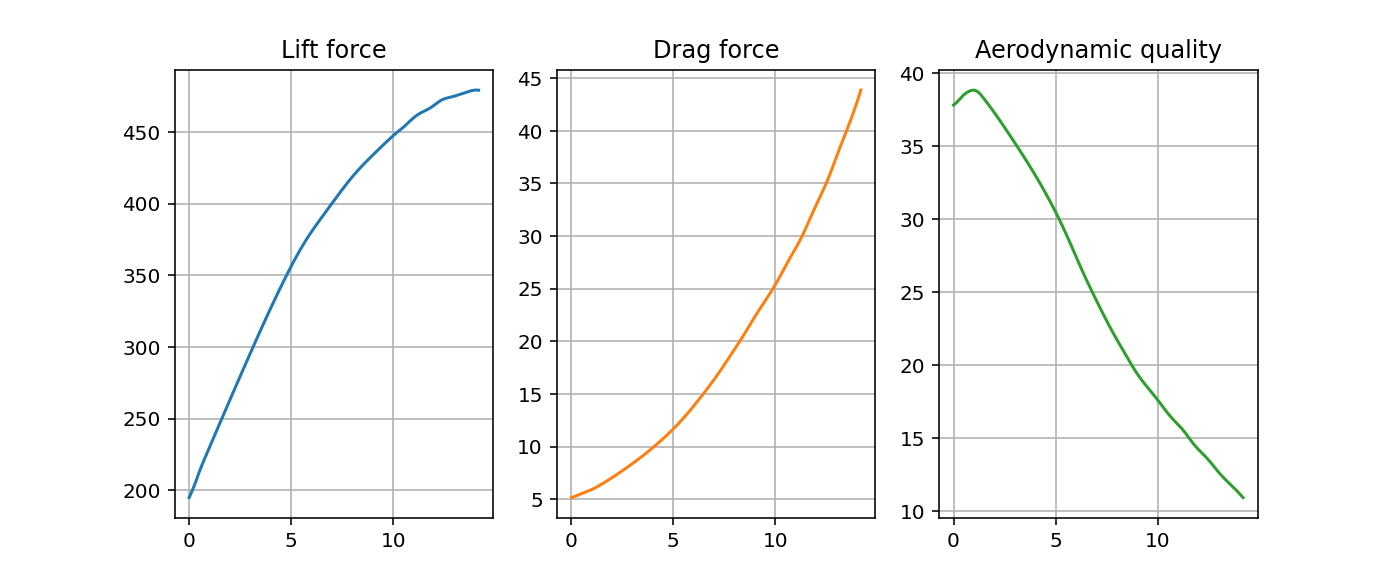

In [26]:
wing_console.plot_aero_forces_by_alpha(VELOCITY)

In [27]:
#wing_console.fit_span_to_required_lift(1, VELOCITY, PAYLOAD_MASS*STANDARD_GRAVITY)

In [28]:
wing_console.stats(1, VELOCITY)

--------------
Flight conditions
--------------
AoA: 1 [degrees]
Velocity: 35 [m/s]
Load factor: 1 
--------------
Wing geometry
--------------
Root chord: 318.5185185185185 [mm]
Tip chord: 159.25925925925924 [mm]
Wing sweep angle: 7.6 [degrees]
Wing span: 2150 [mm]
Wing aspect ratio: 9 
Wing area: 0.513611111111111 [m^2]
--------------
Mass breakdown
--------------
Console mass: 0.45549501374678025 [kg]
Spars mass: 0.14884595662247518 [kg]
Relative spars mass: 32.68 [%]
Foam mass: 0.022446601640634126 [kg]
Relative foam mass: 4.93 [%]
Shell mass: 0.28420245548367096 [kg]
Relative shell mass: 62.39 [%]
Front spar thickness: 2.0 [mm]
Rear spar thickness: 2.0 [mm]
Shell thickness: 0.3 [mm]
Relative bend deflection: 3.871115983208287 [%]
Max bend stress: 49.129184004463184 [MPa]
--------------
Aerodynamics
--------------
Excess console lift force: 110.56264002489968 [N]
Total console lift force: 115.02952020145955 [N]
Total console drag force: 2.961812849672057 [N]
Aerodynamic quality: 38

{'Flight conditions': {'AoA': (1, '[degrees]'),
  'Velocity': (35, '[m/s]'),
  'Load factor': (1, '')},
 'Wing geometry': {'Root chord': (318.5185185185185, '[mm]'),
  'Tip chord': (159.25925925925924, '[mm]'),
  'Wing sweep angle': (7.6, '[degrees]'),
  'Wing span': (2150, '[mm]'),
  'Wing aspect ratio': (9, ''),
  'Wing area': (0.513611111111111, '[m^2]')},
 'Mass breakdown': {'Console mass': (0.45549501374678025, '[kg]'),
  'Spars mass': (0.14884595662247518, '[kg]'),
  'Relative spars mass': ('32.68', '[%]'),
  'Foam mass': (0.022446601640634126, '[kg]'),
  'Relative foam mass': ('4.93', '[%]'),
  'Shell mass': (0.28420245548367096, '[kg]'),
  'Relative shell mass': ('62.39', '[%]'),
  'Front spar thickness': (2.0, '[mm]'),
  'Rear spar thickness': (2.0, '[mm]'),
  'Shell thickness': (0.3, '[mm]'),
  'Relative bend deflection': (3.871115983208287, '[%]'),
  'Max bend stress': (49.129184004463184, '[MPa]')},
 'Aerodynamics': {'Excess console lift force': (110.56264002489968, '[N]'),

In [29]:
alpha_max_lift = wing_console.alpha_max_lift()
alpha_max_lift

16.33211400701113

In [30]:
max_lift_force = wing_console.eval_lift_force(alpha_max_lift, VELOCITY)
max_lift_force

nan

In [31]:
max_drag_force = wing_console.eval_drag_force(alpha_max_lift, VELOCITY)
max_drag_force

nan

In [32]:
max_lift_force/max_drag_force

nan

**Basis aerodynamic parameters based on design methods**

In [33]:
wing_console.CCLS_avg

0.6052493750084537

In [34]:
wing_aero_lift_force = wing_console.lift_force(alpha_max_lift, velocity=VELOCITY)
wing_aero_lift_force

510.6260042058947

In [35]:
wing_aero_drag_force = wing_console.drag_force(alpha_max_lift, velocity=VELOCITY)
wing_aero_drag_force

34.54049946872991

In [36]:
wing_aero_lift_force/wing_aero_drag_force

14.783399547194529

In [37]:
wing_console.eval_aero_midspan(1, VELOCITY)

490.2829754986543

In [38]:
wing_console.console_lift_force_position()

(125.23312038052288, 473.10721607519775)

In [39]:
wing_console.root_chord

318.5185185185185

In [40]:
wing_console.get_aero_center()

(125.23312038052288, -9.678445506818237e-17, 473.10721607519775)

**Transform wing console model**

In [41]:
wing_console.rotate_xyz("Z", 180)
wing_console.rotate_xyz("X", -90)

In [42]:
wing_console.translate(500, 0, 0)

In [43]:
wing_console.mirror("XZ")

In [44]:
assy = cq.Assembly()
assy.add(wing_console.foam, name="foam", color=cq.Color("lightgray"))
assy.add(wing_console.front_spar, name="front_spar", color=cq.Color("yellow"))
assy.add(wing_console.rear_spar, name="rear_spar", color=cq.Color("yellow"))
assy.add(wing_console.shell, name="shell", color=cq.Color("lightskyblue2"))
assy.add(wing_console.aero_center, name="aero_center", color=cq.Color("blue"))
show(assy, angular_tolerance=0.1)

100% ⋮————————————————————————————————————————————————————————————⋮ (5/5)  3.80s


CadViewerWidget(anchor=None, cad_width=800, glass=False, height=600, pinning=False, theme='light', title=None,…

In [45]:
wing_console.get_aero_center()

(374.7668796194771, -473.10721607519775, 5.684341886080802e-14)

### 2. Build wing console with no shell

In [46]:
reload(tsc)

<module 'cquav.wing.twospar_console' from '/home/frantic/splinecloud/demo_copter/cq-uav/cquav/wing/twospar_console.py'>

In [47]:
materials = {"spar": Carbon_laminate, "foam": XPS_foam}

In [48]:
wing_console = tsc.TwoSparWingConsole(
    ccls_surf, span_efficiency, naca4412,
    span=2150, sweep_angle=7.6, aspect_ratio=ar, taper_ratio=tr,
    front_spar_thickness=3.0, rear_spar_thickness=2.0,
    shell_thickness=None, materials=materials
)

In [49]:
assy = cq.Assembly()
assy.add(wing_console.foam, name="foam", color=cq.Color("lightgray"))
assy.add(wing_console.front_spar, name="front_spar", color=cq.Color("yellow"))
assy.add(wing_console.rear_spar, name="rear_spar", color=cq.Color("yellow"))
assy.add(wing_console.aero_center, name="aero_center", color=cq.Color("blue"))
show(assy, angular_tolerance=0.1)

100% ⋮————————————————————————————————————————————————————————————⋮ (4/4)  1.29s


CadViewerWidget(anchor=None, cad_width=800, glass=False, height=600, pinning=False, theme='light', title=None,…

<IPython.core.display.Javascript object>


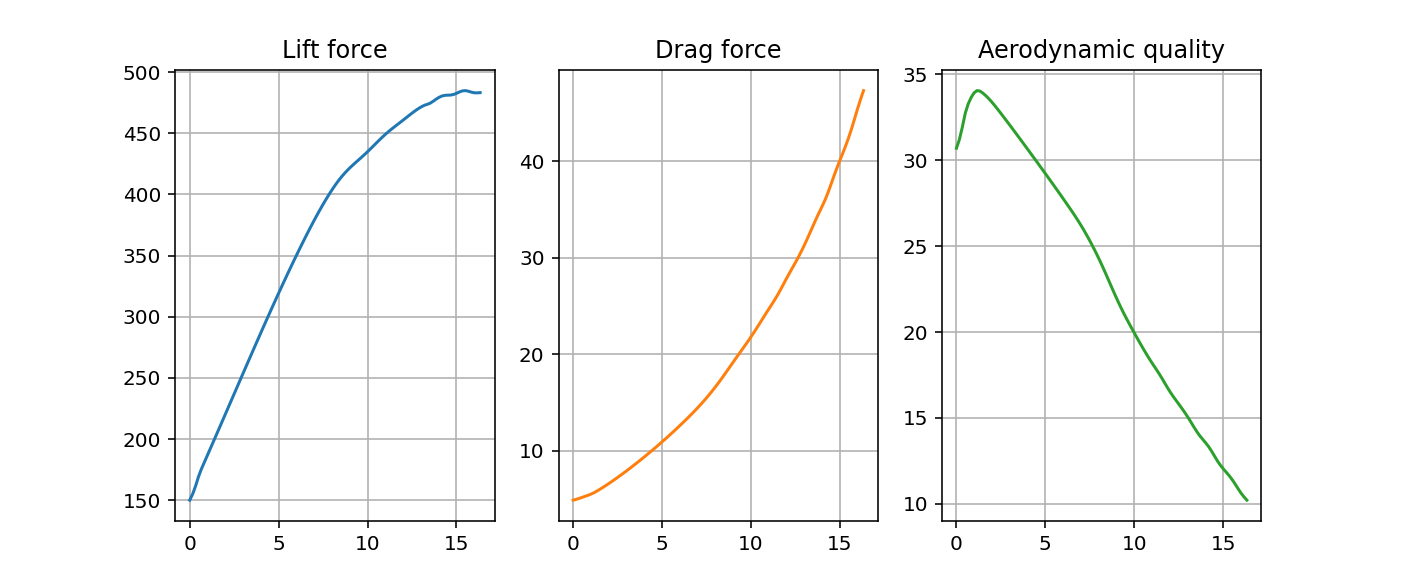

In [50]:
wing_console.plot_aero_forces_by_alpha(VELOCITY)

In [51]:
#wing_console.fit_span_to_required_lift(1, VELOCITY, PAYLOAD_MASS*STANDARD_GRAVITY)

In [52]:
wing_console.stats(1, VELOCITY)

--------------
Flight conditions
--------------
AoA: 1 [degrees]
Velocity: 35 [m/s]
Load factor: 1 
--------------
Wing geometry
--------------
Root chord: 318.5185185185185 [mm]
Tip chord: 159.25925925925924 [mm]
Wing sweep angle: 7.6 [degrees]
Wing span: 2150 [mm]
Wing aspect ratio: 9 
Wing area: 0.513611111111111 [m^2]
--------------
Mass breakdown
--------------
Console mass: 0.21748067411779565 [kg]
Spars mass: 0.1949251080585369 [kg]
Relative spars mass: 89.63 [%]
Foam mass: 0.022555566059258743 [kg]
Relative foam mass: 10.37 [%]
Shell mass: 0 [kg]
Relative shell mass: 0.00 [%]
Front spar thickness: 3.0 [mm]
Rear spar thickness: 2.0 [mm]
Shell thickness: None [mm]
Relative bend deflection: 16.35642528337595 [%]
Max bend stress: 213.96227041219905 [MPa]
--------------
Aerodynamics
--------------
Excess console lift force: 91.31143233578798 [N]
Total console lift force: 93.44418918862526 [N]
Total console drag force: 2.753157126867667 [N]
Aerodynamic quality: 33.94073962459925 
Lif

{'Flight conditions': {'AoA': (1, '[degrees]'),
  'Velocity': (35, '[m/s]'),
  'Load factor': (1, '')},
 'Wing geometry': {'Root chord': (318.5185185185185, '[mm]'),
  'Tip chord': (159.25925925925924, '[mm]'),
  'Wing sweep angle': (7.6, '[degrees]'),
  'Wing span': (2150, '[mm]'),
  'Wing aspect ratio': (9, ''),
  'Wing area': (0.513611111111111, '[m^2]')},
 'Mass breakdown': {'Console mass': (0.21748067411779565, '[kg]'),
  'Spars mass': (0.1949251080585369, '[kg]'),
  'Relative spars mass': ('89.63', '[%]'),
  'Foam mass': (0.022555566059258743, '[kg]'),
  'Relative foam mass': ('10.37', '[%]'),
  'Shell mass': (0, '[kg]'),
  'Relative shell mass': ('0.00', '[%]'),
  'Front spar thickness': (3.0, '[mm]'),
  'Rear spar thickness': (2.0, '[mm]'),
  'Shell thickness': (None, '[mm]'),
  'Relative bend deflection': (16.35642528337595, '[%]'),
  'Max bend stress': (213.96227041219905, '[MPa]')},
 'Aerodynamics': {'Excess console lift force': (91.31143233578798, '[N]'),
  'Total console l

In [53]:
## eval lift curve slope
wing = Wing(ccls_surf, span_efficiency, 15, 9, 2000, naca4412, velocity=VELOCITY)
wing.cl_slope()

0.06583857428186815

In [54]:
wing_console.cl_slope()

0.06585934274818046

In [55]:
alpha_max_lift = wing_console.alpha_max_lift()
alpha_max_lift

16.33211400701113

In [56]:
max_lift_force = wing_console.eval_lift_force(alpha_max_lift, VELOCITY)
max_lift_force

241.65398970233912

In [57]:
max_drag_force = wing_console.eval_drag_force(alpha_max_lift, VELOCITY)
max_drag_force

23.671373540701442

In [58]:
max_lift_force/max_drag_force

10.208701632240741

**Basis aerodynamic parameters based on design methods**

In [59]:
wing_console.CCLS_avg

0.6052493750084537

In [60]:
wing_aero_lift_force = wing_console.lift_force(alpha_max_lift, velocity=VELOCITY)
wing_aero_lift_force

510.6260042058947

In [61]:
wing_aero_drag_force = wing_console.drag_force(alpha_max_lift, velocity=VELOCITY)
wing_aero_drag_force

34.54049946872991

In [62]:
wing_aero_lift_force/wing_aero_drag_force

14.783399547194529

In [63]:
wing_console.eval_aero_midspan(1, VELOCITY)

471.30097678625066

In [64]:
wing_console.console_lift_force_position()

(125.23312038052288, 473.10721607519775)

**Transform wing console model**

In [65]:
wing_console.rotate_xyz("Z", 180)
wing_console.rotate_xyz("X", -90)

In [66]:
wing_console.translate(500, 0, 0)

In [67]:
wing_console.mirror("XZ")

In [68]:
assy = cq.Assembly()
assy.add(wing_console.foam, name="foam", color=cq.Color("lightgray"))
assy.add(wing_console.front_spar, name="front_spar", color=cq.Color("yellow"))
assy.add(wing_console.rear_spar, name="rear_spar", color=cq.Color("yellow"))
assy.add(wing_console.aero_center, name="aero_center", color=cq.Color("blue"))
show(assy, angular_tolerance=0.1)

100% ⋮————————————————————————————————————————————————————————————⋮ (4/4)  1.26s


CadViewerWidget(anchor=None, cad_width=800, glass=False, height=600, pinning=False, theme='light', title=None,…

### 3. Change geometry

In [69]:
wing_console.set_new_aspect_ratio(6)

Setting new aspect ratio. AR = 6


In [70]:
wing_console.build_geometry()

In [71]:
wing_console.stats(1, VELOCITY)

--------------
Flight conditions
--------------
AoA: 1 [degrees]
Velocity: 35 [m/s]
Load factor: 1 
--------------
Wing geometry
--------------
Root chord: 477.77777777777777 [mm]
Tip chord: 238.88888888888889 [mm]
Wing sweep angle: 7.6 [degrees]
Wing span: 2150 [mm]
Wing aspect ratio: 6 
Wing area: 0.7704166666666666 [m^2]
--------------
Mass breakdown
--------------
Console mass: 0.3435686183979781 [kg]
Spars mass: 0.29239631910502284 [kg]
Relative spars mass: 85.11 [%]
Foam mass: 0.051172299292955234 [kg]
Relative foam mass: 14.89 [%]
Shell mass: 0 [kg]
Relative shell mass: 0.00 [%]
Front spar thickness: 3.0 [mm]
Rear spar thickness: 2.0 [mm]
Shell thickness: None [mm]
Relative bend deflection: 6.686332932720812 [%]
Max bend stress: 130.48081285135993 [MPa]
--------------
Aerodynamics
--------------
Excess console lift force: 124.25664138039183 [N]
Total console lift force: 127.62589857200436 [N]
Total console drag force: 4.17411168767363 [N]
Aerodynamic quality: 30.575583051332888 

{'Flight conditions': {'AoA': (1, '[degrees]'),
  'Velocity': (35, '[m/s]'),
  'Load factor': (1, '')},
 'Wing geometry': {'Root chord': (477.77777777777777, '[mm]'),
  'Tip chord': (238.88888888888889, '[mm]'),
  'Wing sweep angle': (7.6, '[degrees]'),
  'Wing span': (2150, '[mm]'),
  'Wing aspect ratio': (6, ''),
  'Wing area': (0.7704166666666666, '[m^2]')},
 'Mass breakdown': {'Console mass': (0.3435686183979781, '[kg]'),
  'Spars mass': (0.29239631910502284, '[kg]'),
  'Relative spars mass': ('85.11', '[%]'),
  'Foam mass': (0.051172299292955234, '[kg]'),
  'Relative foam mass': ('14.89', '[%]'),
  'Shell mass': (0, '[kg]'),
  'Relative shell mass': ('0.00', '[%]'),
  'Front spar thickness': (3.0, '[mm]'),
  'Rear spar thickness': (2.0, '[mm]'),
  'Shell thickness': (None, '[mm]'),
  'Relative bend deflection': (6.686332932720812, '[%]'),
  'Max bend stress': (130.48081285135993, '[MPa]')},
 'Aerodynamics': {'Excess console lift force': (124.25664138039183, '[N]'),
  'Total consol

In [72]:
assy = cq.Assembly()
assy.add(wing_console.foam, name="foam", color=cq.Color("lightgray"))
assy.add(wing_console.front_spar, name="front_spar", color=cq.Color("yellow"))
assy.add(wing_console.rear_spar, name="rear_spar", color=cq.Color("yellow"))
assy.add(wing_console.aero_center, name="aero_center", color=cq.Color("blue"))
show(assy, angular_tolerance=0.1)

100% ⋮————————————————————————————————————————————————————————————⋮ (4/4)  0.88s


CadViewerWidget(anchor=None, cad_width=800, glass=False, height=600, pinning=False, theme='light', title=None,…

In [73]:
wing_console.length_cut(100, components="all", merge_result=False, group_on_workplane=True)

CadViewerWidget(anchor=None, cad_width=800, glass=False, height=600, pinning=False, theme='light', title=None,…

In [74]:
wing_console.rotate_xyz("X", 90)

In [75]:
wing_console.foam

CadViewerWidget(anchor=None, cad_width=800, glass=False, height=600, pinning=False, theme='light', title=None,…

In [76]:
wing_console.length_cut(2000, components="all", merge_result=False, group_on_workplane=True)

CadViewerWidget(anchor=None, cad_width=800, glass=False, height=600, pinning=False, theme='light', title=None,…

### 4. Build wing console with no shell and variable airfoil

In [77]:
materials = {"spar": Carbon_laminate, "foam": XPS_foam}

In [78]:
wing_console = tsc.TwoSparWingConsole(
    ccls_surf, span_efficiency, naca4415, tip_airfoil=naca4412,
    span=2150, sweep_angle=7.6, aspect_ratio=ar, taper_ratio=tr,
    front_spar_thickness=2.0, rear_spar_thickness=2.0,
    shell_thickness=None, materials=materials
)

In [79]:
assy = cq.Assembly()
assy.add(wing_console.foam, name="foam", color=cq.Color("lightgray"))
assy.add(wing_console.front_spar, name="front_spar", color=cq.Color("yellow"))
assy.add(wing_console.rear_spar, name="rear_spar", color=cq.Color("yellow"))
assy.add(wing_console.aero_center, name="aero_center", color=cq.Color("blue"))
show(assy, angular_tolerance=0.1)

100% ⋮————————————————————————————————————————————————————————————⋮ (4/4)  1.02s


CadViewerWidget(anchor=None, cad_width=800, glass=False, height=600, pinning=False, theme='light', title=None,…

<IPython.core.display.Javascript object>


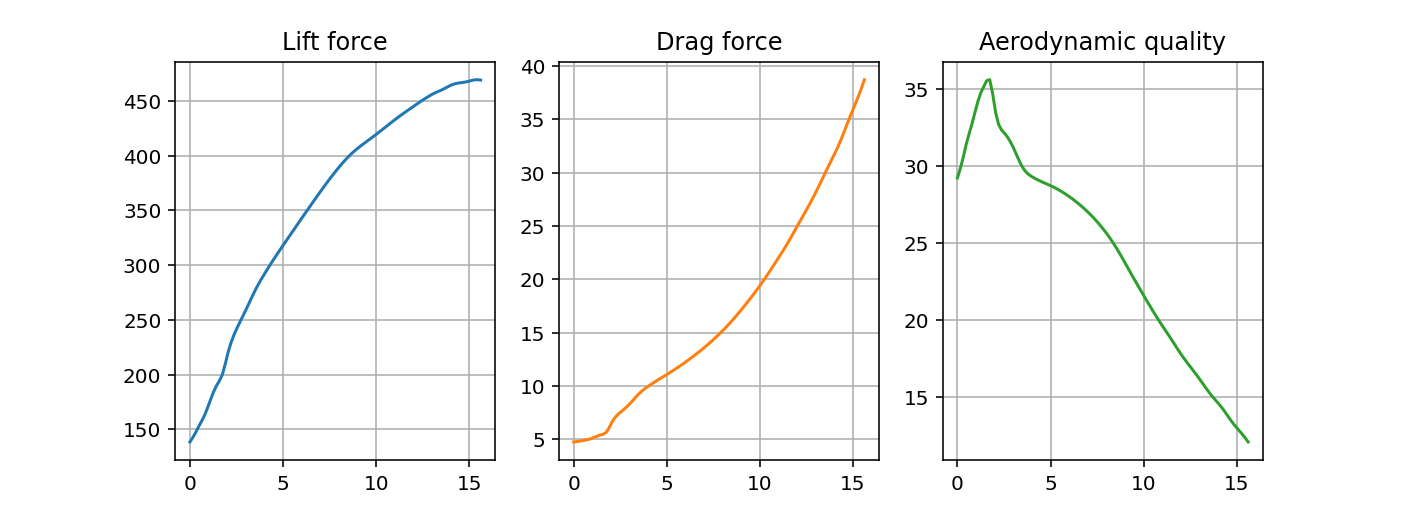

In [80]:
wing_console.plot_aero_forces_by_alpha(VELOCITY)

In [81]:
#wing_console.fit_span_to_required_lift(1, VELOCITY, PAYLOAD_MASS*STANDARD_GRAVITY, preserve_box_thickness=True)

In [82]:
wing_console.stats(1, VELOCITY)

--------------
Flight conditions
--------------
AoA: 1 [degrees]
Velocity: 35 [m/s]
Load factor: 1 
--------------
Wing geometry
--------------
Root chord: 318.5185185185185 [mm]
Tip chord: 159.25925925925924 [mm]
Wing sweep angle: 7.6 [degrees]
Wing span: 2150 [mm]
Wing aspect ratio: 9 
Wing area: 0.513611111111111 [m^2]
--------------
Mass breakdown
--------------
Console mass: 0.1996881639250889 [kg]
Spars mass: 0.17327100071337265 [kg]
Relative spars mass: 86.77 [%]
Foam mass: 0.02641716321171625 [kg]
Relative foam mass: 13.23 [%]
Shell mass: 0 [kg]
Relative shell mass: 0.00 [%]
Front spar thickness: 2.0 [mm]
Rear spar thickness: 2.0 [mm]
Shell thickness: None [mm]
Relative bend deflection: 22.49094283001998 [%]
Max bend stress: 297.08754521283845 [MPa]
--------------
Aerodynamics
--------------
Excess console lift force: 84.15454869543977 [N]
Total console lift force: 86.11282062819575 [N]
Total console drag force: 2.5505172821352233 [N]
Aerodynamic quality: 33.76288458477115 
Lif

{'Flight conditions': {'AoA': (1, '[degrees]'),
  'Velocity': (35, '[m/s]'),
  'Load factor': (1, '')},
 'Wing geometry': {'Root chord': (318.5185185185185, '[mm]'),
  'Tip chord': (159.25925925925924, '[mm]'),
  'Wing sweep angle': (7.6, '[degrees]'),
  'Wing span': (2150, '[mm]'),
  'Wing aspect ratio': (9, ''),
  'Wing area': (0.513611111111111, '[m^2]')},
 'Mass breakdown': {'Console mass': (0.1996881639250889, '[kg]'),
  'Spars mass': (0.17327100071337265, '[kg]'),
  'Relative spars mass': ('86.77', '[%]'),
  'Foam mass': (0.02641716321171625, '[kg]'),
  'Relative foam mass': ('13.23', '[%]'),
  'Shell mass': (0, '[kg]'),
  'Relative shell mass': ('0.00', '[%]'),
  'Front spar thickness': (2.0, '[mm]'),
  'Rear spar thickness': (2.0, '[mm]'),
  'Shell thickness': (None, '[mm]'),
  'Relative bend deflection': (22.49094283001998, '[%]'),
  'Max bend stress': (297.08754521283845, '[MPa]')},
 'Aerodynamics': {'Excess console lift force': (84.15454869543977, '[N]'),
  'Total console li

In [83]:
wing_console.cl_slope()

0.06983267681649029

In [84]:
wing = Wing(ccls_surf, span_efficiency, 15, 9, 2000, naca4415, velocity=VELOCITY)
wing.cl_slope()

0.07216256089008918

In [85]:
wing = Wing(ccls_surf, span_efficiency, 15, 9, 2000, naca4412, velocity=VELOCITY)
wing.cl_slope()

0.06583857428186815

### 5. Build wing console with chords aligned by 0.25

In [86]:
wing_console = tsc.TwoSparWingConsole(
    ccls_surf, span_efficiency, naca4415, tip_airfoil=naca4412,
    span=2150, sweep_angle=None, chord_align_factor=0.25, aspect_ratio=ar, taper_ratio=tr,
    front_spar_thickness=2.0, rear_spar_thickness=2.0,
    shell_thickness=None, materials=materials
)

In [87]:
assy = cq.Assembly()
assy.add(wing_console.foam, name="foam", color=cq.Color("lightgray"))
assy.add(wing_console.front_spar, name="front_spar", color=cq.Color("yellow"))
assy.add(wing_console.rear_spar, name="rear_spar", color=cq.Color("yellow"))
assy.add(wing_console.aero_center, name="aero_center", color=cq.Color("blue"))
show(assy, angular_tolerance=0.1)

100% ⋮————————————————————————————————————————————————————————————⋮ (4/4)  1.03s


CadViewerWidget(anchor=None, cad_width=800, glass=False, height=600, pinning=False, theme='light', title=None,…

In [88]:
wing_console.stats(1, VELOCITY)

--------------
Flight conditions
--------------
AoA: 1 [degrees]
Velocity: 35 [m/s]
Load factor: 1 
--------------
Wing geometry
--------------
Root chord: 318.5185185185185 [mm]
Tip chord: 159.25925925925924 [mm]
Wing sweep angle: 2.1210963966614536 [degrees]
Wing span: 2150 [mm]
Wing aspect ratio: 9 
Wing area: 0.513611111111111 [m^2]
--------------
Mass breakdown
--------------
Console mass: 0.19968816392508826 [kg]
Spars mass: 0.17327100071337204 [kg]
Relative spars mass: 86.77 [%]
Foam mass: 0.02641716321171622 [kg]
Relative foam mass: 13.23 [%]
Shell mass: 0 [kg]
Relative shell mass: 0.00 [%]
Front spar thickness: 2.0 [mm]
Rear spar thickness: 2.0 [mm]
Shell thickness: None [mm]
Relative bend deflection: 22.677196139510635 [%]
Max bend stress: 266.8423644511401 [MPa]
--------------
Aerodynamics
--------------
Excess console lift force: 84.15454869543979 [N]
Total console lift force: 86.11282062819575 [N]
Total console drag force: 2.5505172821352233 [N]
Aerodynamic quality: 33.762

{'Flight conditions': {'AoA': (1, '[degrees]'),
  'Velocity': (35, '[m/s]'),
  'Load factor': (1, '')},
 'Wing geometry': {'Root chord': (318.5185185185185, '[mm]'),
  'Tip chord': (159.25925925925924, '[mm]'),
  'Wing sweep angle': (2.1210963966614536, '[degrees]'),
  'Wing span': (2150, '[mm]'),
  'Wing aspect ratio': (9, ''),
  'Wing area': (0.513611111111111, '[m^2]')},
 'Mass breakdown': {'Console mass': (0.19968816392508826, '[kg]'),
  'Spars mass': (0.17327100071337204, '[kg]'),
  'Relative spars mass': ('86.77', '[%]'),
  'Foam mass': (0.02641716321171622, '[kg]'),
  'Relative foam mass': ('13.23', '[%]'),
  'Shell mass': (0, '[kg]'),
  'Relative shell mass': ('0.00', '[%]'),
  'Front spar thickness': (2.0, '[mm]'),
  'Rear spar thickness': (2.0, '[mm]'),
  'Shell thickness': (None, '[mm]'),
  'Relative bend deflection': (22.677196139510635, '[%]'),
  'Max bend stress': (266.8423644511401, '[MPa]')},
 'Aerodynamics': {'Excess console lift force': (84.15454869543979, '[N]'),
  '

### 6. Build wing console with initial alpha and twist

In [89]:
reload(tsc)

<module 'cquav.wing.twospar_console' from '/home/frantic/splinecloud/demo_copter/cq-uav/cquav/wing/twospar_console.py'>

In [90]:
materials = {"spar": Carbon_laminate, "shell": Fiberglass_laminate, "foam": XPS_foam}

In [91]:
wing_console = tsc.TwoSparWingConsole(
    ccls_surf, span_efficiency, naca4415, tip_airfoil=naca4412,
    span=2150, sweep_angle=7.6, aspect_ratio=ar, taper_ratio=tr,
    front_spar_thickness=2.0, rear_spar_thickness=2.0, 
    root_twist_angle=4, tip_twist_angle=4,
    shell_thickness=0.3, materials=materials
)

In [92]:
assy = cq.Assembly()
assy.add(wing_console.foam, name="foam", color=cq.Color("lightgray"))
assy.add(wing_console.front_spar, name="front_spar", color=cq.Color("yellow"))
assy.add(wing_console.rear_spar, name="rear_spar", color=cq.Color("yellow"))
assy.add(wing_console.shell, name="shell", color=cq.Color("lightskyblue2"))
assy.add(wing_console.aero_center, name="aero_center", color=cq.Color("blue"))
show(assy, angular_tolerance=0.1)

100% ⋮————————————————————————————————————————————————————————————⋮ (5/5)  3.32s


CadViewerWidget(anchor=None, cad_width=800, glass=False, height=600, pinning=False, theme='light', title=None,…

<IPython.core.display.Javascript object>


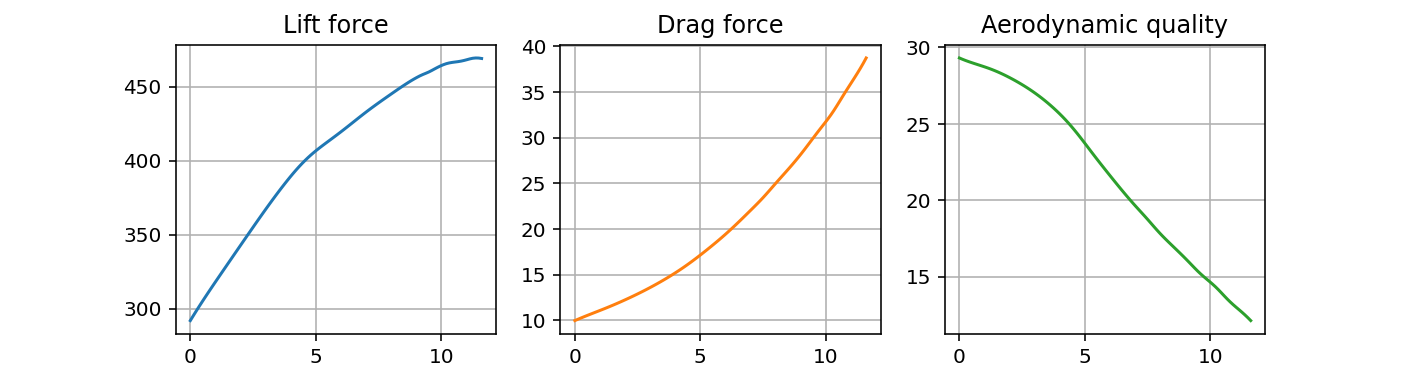

In [93]:
wing_console.plot_aero_forces_by_alpha(VELOCITY)

In [94]:
wing_console.fit_span_to_required_lift(1, VELOCITY, PAYLOAD_MASS*STANDARD_GRAVITY)

Finding span for the required lift force = 196.13299999999998
Setting new span. Span = 3179.3348877508197
Current span: 3179.3348877508197
Mass: 1.0886974724652574, [kg]
Excess console lift force: 339.3779080530852, [N]
Lift force error: 482.62281610617043, [N]

Setting new span. Span = 5020.665112249179
Current span: 5020.665112249179
Mass: 2.8384413435516063, [kg]
Excess console lift force: 848.3322472744634, [N]
Lift force error: 1500.5314945489267, [N]

Setting new span. Span = 2041.3302244983595
Current span: 2041.3302244983595
Mass: 0.4361878094113445, [kg]
Excess console lift force: 138.9599571789764, [N]
Lift force error: 81.78691435795281, [N]

Setting new span. Span = 1338.0046632524604
Current span: 1338.0046632524604
Mass: 0.18404459188044509, [kg]
Excess console lift force: 59.45804543023409, [N]
Lift force error: -77.21690913953181, [N]

Setting new span. Span = 1672.3642657071007
Current span: 1672.3642657071007
Mass: 0.29001105196503596, [kg]
Excess console lift force: 

1717.1033150413332

In [95]:
wing_console.stats(1, VELOCITY)

--------------
Flight conditions
--------------
AoA: 1 [degrees]
Velocity: 35 [m/s]
Load factor: 1 
--------------
Wing geometry
--------------
Root chord: 254.38567630241974 [mm]
Tip chord: 127.19283815120987 [mm]
Wing sweep angle: 7.6 [degrees]
Wing span: 1717.1033150413332 [mm]
Wing aspect ratio: 9 
Wing area: 0.3276048660584373 [m^2]
--------------
Mass breakdown
--------------
Console mass: 0.30608651529149766 [kg]
Spars mass: 0.11056580331401208 [kg]
Relative spars mass: 36.12 [%]
Foam mass: 0.013059622734682239 [kg]
Relative foam mass: 4.27 [%]
Shell mass: 0.18246108924280333 [kg]
Relative shell mass: 59.61 [%]
Front spar thickness: 2.0 [mm]
Rear spar thickness: 2.0 [mm]
Shell thickness: 0.3 [mm]
Relative bend deflection: 2.304449019725861 [%]
Max bend stress: 20.76185818547382 [MPa]
--------------
Aerodynamics
--------------
Excess console lift force: 98.06230122666857 [N]
Total console lift force: 101.06398455185193 [N]
Total console drag force: 3.638124607421626 [N]
Aerodynam

{'Flight conditions': {'AoA': (1, '[degrees]'),
  'Velocity': (35, '[m/s]'),
  'Load factor': (1, '')},
 'Wing geometry': {'Root chord': (254.38567630241974, '[mm]'),
  'Tip chord': (127.19283815120987, '[mm]'),
  'Wing sweep angle': (7.6, '[degrees]'),
  'Wing span': (1717.1033150413332, '[mm]'),
  'Wing aspect ratio': (9, ''),
  'Wing area': (0.3276048660584373, '[m^2]')},
 'Mass breakdown': {'Console mass': (0.30608651529149766, '[kg]'),
  'Spars mass': (0.11056580331401208, '[kg]'),
  'Relative spars mass': ('36.12', '[%]'),
  'Foam mass': (0.013059622734682239, '[kg]'),
  'Relative foam mass': ('4.27', '[%]'),
  'Shell mass': (0.18246108924280333, '[kg]'),
  'Relative shell mass': ('59.61', '[%]'),
  'Front spar thickness': (2.0, '[mm]'),
  'Rear spar thickness': (2.0, '[mm]'),
  'Shell thickness': (0.3, '[mm]'),
  'Relative bend deflection': (2.304449019725861, '[%]'),
  'Max bend stress': (20.76185818547382, '[MPa]')},
 'Aerodynamics': {'Excess console lift force': (98.062301226